# T10 · Clustering (K-Means · เลือก k · Centroid/Profile · Cohesion/Separation · Hierarchical/Dendrogram)

**ใช้เมื่อโจทย์ถาม:** แบ่งกลุ่ม (ไม่มี label) · เตรียมข้อมูลสำหรับ clustering (ตัด id, normalize) · K-Means + parameters (k, n_init, max_iter) ·
เลือกจำนวน cluster (elbow/WCSS, silhouette, Davies–Bouldin) · ตีความ centroid / ตั้งชื่อกลุ่ม · จุดใหม่อยู่กลุ่มไหน ·
cohesion / separation · วาดบน PCA 2D · hierarchical clustering + dendrogram · เทียบกับ label จริง (ถ้ามี)

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** — `ID_COL`, `FEATURES`, `K_FINAL` (k ที่โจทย์กำหนด หรือ None = เลือกอัตโนมัติจาก silhouette) |
| 2 | Run All · ตาราง k §2 · centroid §3 · จุดใหม่ §4 |
| 3 | โจทย์ให้คำนวณ K-Means มือ (จุดเล็ก ๆ + seed) → §9 แก้ `HAND_POINTS`, `HAND_INIT` |

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH = "../data/utilities.csv"
ID_COL    = "Company"        # ชื่อ/รหัสแถว (ไม่ใช้คำนวณ ใช้ติดป้าย)
LABEL_COL = None             # ถ้าข้อมูลมี class จริง (ไว้เทียบหลัง cluster เท่านั้น ห้ามใช้ตอน cluster) · None = ไม่มี
DROP_COLS = []               # คอลัมน์ที่ไม่ใช้
FEATURES  = None             # list feature ที่ใช้ cluster · None = ตัวเลขทุกคอลัมน์ที่เหลือ
SCALE     = "standard"       # "standard" (z-score) | "minmax" | None — K-Means ใช้ระยะทาง ควร scale
K_RANGE   = range(2, 9)      # ช่วง k ที่ลอง
K_FINAL   = 4                # k ที่ใช้จริง (None = เลือก k ที่ silhouette สูงสุด)
N_INIT    = 50               # จำนวนรอบสุ่ม centroid เริ่มต้น (เลือกรอบที่ WCSS ต่ำสุด)
MAX_ITER  = 300
NEW_POINT = {"Fixed_charge": 1.10, "RoR": 11.0, "Cost": 160, "Load_factor": 56, "Demand_growth": 3.0,
             "Sales": 14000, "Nuclear": 0, "Fuel_Cost": 0.70}    # None = ข้าม
LINKAGE   = "ward"           # hierarchical: "ward" | "complete" | "average" | "single"
SEED = 42
MISSING_MARKERS, SHEET, CSV_SEP = ["?", "", " ", "NA"], 0, ","

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        for enc in ["utf-8-sig", "cp874", "latin1"]:      # utf-8 (ตัด BOM) → ภาษาไทยจาก Excel (cp874) → อื่น ๆ
            try:
                df = pd.read_csv(path, sep=sep, encoding=enc)
                break
            except UnicodeDecodeError:
                continue
        if df.shape[1] == 1 and ";" in str(df.columns[0]):  # ไฟล์คั่นด้วย ; แต่ตั้ง CSV_SEP = ","
            df = pd.read_csv(path, sep=";", encoding=enc)
            print("ℹ️ ไฟล์นี้คั่นด้วย ';' → อ่านใหม่ด้วย sep=';'")
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def fix_col(df, col, kind="any", i=0):
    """คอลัมน์ที่ตั้งไว้ใน ✏️ ไม่มีในข้อมูลนี้ → เลือกคอลัมน์ชนิดเดียวกันให้ชั่วคราว (Run All ไม่หยุด) — ควรแก้ ✏️ ให้ตรงโจทย์
    kind: "num" = ตัวเลขต่อเนื่อง · "cat" = หมวดหมู่ (ค่าไม่เกิน 20 แบบ) · "any" """
    if col is None or col in df.columns:
        return col
    skip = {ID_COL}
    nums = [c for c in num_cols(df) if c not in skip]
    if kind == "num":
        pool = [c for c in nums if df[c].nunique() > 10] or nums
    elif kind == "cat":
        few = [c for c in df.columns if c not in skip and df[c].nunique() <= 20]
        pool = [c for c in few if c not in nums] + [c for c in few if c in nums]
    else:
        pool = [c for c in df.columns if c not in skip]
    new = pool[min(i, len(pool) - 1)] if pool else None
    print(f"⚠️ ไม่มีคอลัมน์ {col!r} ในข้อมูลนี้ → ใช้ {new!r} แทนชั่วคราว (แก้บรรทัด ✏️ ให้ตรงโจทย์)")
    return new


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale="config", num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    if scale == "config":                      # ไม่ระบุ → ใช้ SCALE จาก CONFIG · ส่ง None = ไม่ scale
        scale = SCALE
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale="config", **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": float(mean_absolute_error(y_true, y_pred)), "MSE": float(mse), "RMSE": float(np.sqrt(mse)),
            "R2": float(r2_score(y_true, y_pred))}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 5


## §1 เตรียมข้อมูล: ตัด id/label · เลือก feature ตัวเลข · จัดการค่าว่าง · **scale**
K-Means ใช้ระยะ Euclidean → ตัวแปรหน่วยใหญ่ (เช่น Sales หลักหมื่น) จะครอบงำถ้าไม่ scale

In [3]:
df = load_data(DATA_PATH)
check(df)
skip = [c for c in [ID_COL, LABEL_COL] + list(DROP_COLS) if c]
feats = FEATURES or [c for c in num_cols(df) if c not in skip]
cat_in = [c for c in df.columns if c not in skip + feats]
if cat_in:
    print("⚠️ คอลัมน์หมวดหมู่ที่ไม่ได้ใช้:", cat_in, "(ถ้าต้องใช้ → one-hot ก่อน: df = pd.get_dummies(df, columns=[...], dtype=int) แล้วใส่ใน FEATURES)")
data = df.dropna(subset=feats).reset_index(drop=True)
names = data[ID_COL].astype(str) if ID_COL and ID_COL in data else pd.Series(data.index.astype(str))
Xc = data[feats]
scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(SCALE)
Z = scaler.fit_transform(Xc) if scaler else Xc.values
print(f"ใช้ {len(feats)} feature: {feats} · {len(data)} แถว · scale = {SCALE}")
display(pd.concat({"original": Xc.agg(["mean", "std", "min", "max"]),
                   "scaled": pd.DataFrame(Z, columns=feats).agg(["mean", "std", "min", "max"])}).round(3))

โหลด ../data/utilities.csv → 22 แถว × 9 คอลัมน์
shape: (22, 9) | แถวซ้ำ: 0


,dtype,missing,missing_%,unique,example
Company,str,0,0.0000,22,Arizona
Fixed_charge,float64,0,0.0000,21,1.0600
RoR,float64,0,0.0000,21,9.2000
Cost,int64,0,0.0000,21,151
Load_factor,float64,0,0.0000,20,54.4000
Demand_growth,float64,0,0.0000,19,1.6000
Sales,int64,0,0.0000,22,9077
Nuclear,float64,0,0.0000,11,0.0000
Fuel_Cost,float64,0,0.0000,22,0.6280


ใช้ 8 feature: ['Fixed_charge', 'RoR', 'Cost', 'Load_factor', 'Demand_growth', 'Sales', 'Nuclear', 'Fuel_Cost'] · 22 แถว · scale = standard


Fixed_charge     RoR     Cost  Load_factor  Demand_growth       Sales  Nuclear  Fuel_Cost
original mean        1.1140 10.7360 168.1820      56.9770         3.2410  8,914.0450  12.0000     1.1030
         std         0.1850  2.2440  41.1910       4.4610         3.1180  3,549.9840  16.7920     0.5560
         min         0.7500  6.4000  96.0000      49.8000        -2.2000  3,300.0000   0.0000     0.3090
         max         1.4900 15.4000 252.0000      67.6000         9.2000 17,441.0000  50.2000     2.1160
scaled   mean        0.0000 -0.0000  -0.0000       0.0000        -0.0000      0.0000   0.0000    -0.0000
         std         1.0240  1.0240   1.0240       1.0240         1.0240      1.0240   1.0240     1.0240
         min        -2.0200 -1.9780  -1.7940      -1.6470        -1.7860     -1.6190  -0.7310    -1.4610
         max         2.0850  2.1270   2.0830       2.4370         1.9560      2.4580   2.3280     1.8650

**✍️ คำตอบ §1:** ตัด `…` (id / label) · ใช้ … feature ตัวเลข · normalize (z-score) เพราะหน่วยต่างกันมาก (std ของ … = … vs … = …) ไม่งั้น … จะครอบงำระยะทาง

## §2 เลือกจำนวน cluster k
| เกณฑ์ | ดูอะไร | ดี = |
|---|---|---|
| **WCSS / SSE (inertia)** — cohesion | ผลรวมระยะ² ถึง centroid | หา "ข้อศอก" (elbow) ที่ลดลงช้าลง |
| **Silhouette** (−1..1) | cohesion + separation ต่อจุด | สูงสุด |
| **Davies–Bouldin** | ความกระจายในกลุ่ม / ระยะระหว่างกลุ่ม | ต่ำสุด |

,k,WCSS (inertia),avg within-centroid dist²,silhouette,davies_bouldin,sizes,WCSS drop
0,2,137.4498,6.2477,0.1853,1.6215,"[15, 7]",NaN
1,3,106.5540,4.8434,0.2301,1.3667,"[12, 7, 3]",30.8958
2,4,84.2110,3.8278,0.2341,1.1766,"[7, 7, 5, 3]",22.3431
3,5,70.6162,3.2098,0.2477,1.0001,"[7, 6, 5, 3, 1]",13.5948
4,6,60.9229,2.7692,0.2406,0.9038,"[7, 5, 5, 3, 1, 1]",9.6933
5,7,51.8788,2.3581,0.2297,0.8710,"[6, 5, 4, 3, 2, 1, 1]",9.0441
6,8,44.2511,2.0114,0.2194,0.8352,"[6, 4, 4, 3, 2, 1, 1, 1]",7.6276


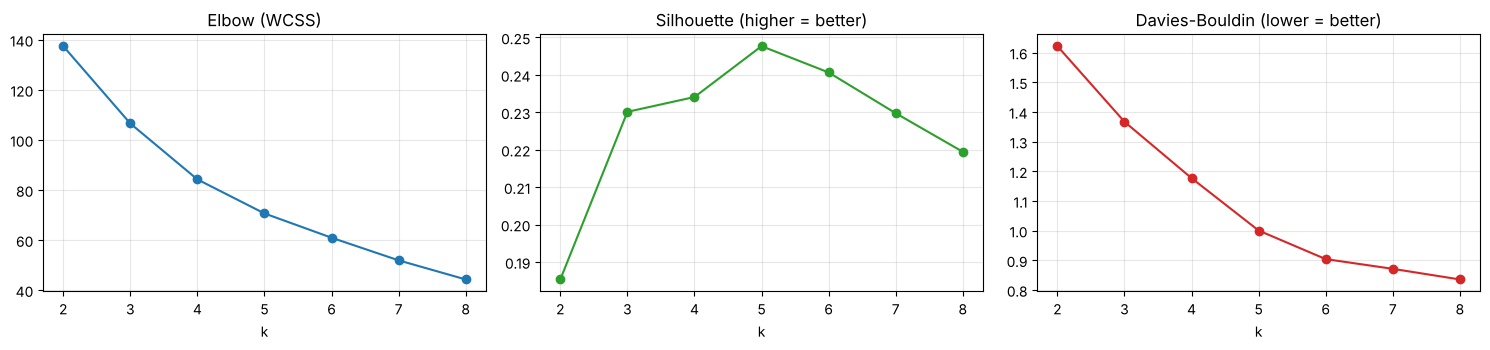

✍️ silhouette สูงสุดที่ k = 5 (0.2477) · Davies–Bouldin ต่ำสุดที่ k = 8 (0.8352) · ใช้ k = 4


In [4]:
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, max_iter=MAX_ITER, random_state=SEED).fit(Z)
    rows.append({"k": k, "WCSS (inertia)": km.inertia_, "avg within-centroid dist²": km.inertia_ / len(Z),
                 "silhouette": silhouette_score(Z, km.labels_), "davies_bouldin": davies_bouldin_score(Z, km.labels_),
                 "sizes": sorted(np.bincount(km.labels_).tolist(), reverse=True)})
kt = pd.DataFrame(rows)
kt["WCSS drop"] = -kt["WCSS (inertia)"].diff()
display(kt.round(4))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(kt.k, kt["WCSS (inertia)"], "o-"); ax[0].set(title="Elbow (WCSS)", xlabel="k")
ax[1].plot(kt.k, kt.silhouette, "o-", color="C2"); ax[1].set(title="Silhouette (higher = better)", xlabel="k")
ax[2].plot(kt.k, kt.davies_bouldin, "o-", color="C3"); ax[2].set(title="Davies-Bouldin (lower = better)", xlabel="k")
plt.tight_layout(); plt.show()
k_sil = int(kt.loc[kt.silhouette.idxmax(), "k"]); k_db = int(kt.loc[kt.davies_bouldin.idxmin(), "k"])
K = K_FINAL or k_sil
print(f"✍️ silhouette สูงสุดที่ k = {k_sil} ({kt.silhouette.max():.4f}) · Davies–Bouldin ต่ำสุดที่ k = {k_db} ({kt.davies_bouldin.min():.4f}) · ใช้ k = {K}")

**✍️ คำตอบ §2:** WCSS ลดลงเร็วจนถึง k = … แล้วลดช้าลง (elbow) · silhouette สูงสุดที่ k = … · DB ต่ำสุดที่ k = … · เลือก k = … เพราะ … (ตัวเลข + ตีความได้ทางธุรกิจ)

## §3 K-Means ด้วย k ที่เลือก → สมาชิก · centroid (หน่วยเดิม + z-score) · profile · ตั้งชื่อกลุ่ม

k = 4 · WCSS = 84.2110 · silhouette = 0.2341 · iterations = 3
Cluster 0 (7): Arizona, Central, Florida, Kentucky, Oklahoma, Southern, Texas
Cluster 1 (7): Boston, NY, Hawaiian, New England, Pacific, San Diego, United
Cluster 2 (5): Commonwealth, Madison, Northern, Wisconsin, Virginia
Cluster 3 (3): Idaho, Nevada, Puget

centroid (หน่วยเดิม) + ค่าเฉลี่ยรวม:


,Fixed_charge,RoR,Cost,Load_factor,Demand_growth,Sales,Nuclear,Fuel_Cost
0,1.2070,12.4860,127.5710,55.4710,1.7140,"10,163.1430",3.2140,0.8740
1,1.0700,9.2570,178.7140,60.5430,3.0710,"5,859.4290",7.1570,1.7980
2,1.1120,11.4800,177.2000,55.3800,3.7600,"7,487.4000",38.2800,0.7720
3,1.0030,8.8670,223.3330,54.8330,6.3330,"15,504.6670",0.0000,0.5660
ALL,1.1140,10.7360,168.1820,56.9770,3.2410,"8,914.0450",12.0000,1.1030


centroid (scaled; + = สูงกว่าค่าเฉลี่ย, − = ต่ำกว่า):


,Fixed_charge,RoR,Cost,Load_factor,Demand_growth,Sales,Nuclear,Fuel_Cost
0,0.5160,0.7980,-1.0090,-0.3450,-0.5010,0.3600,-0.5360,-0.4200
1,-0.2450,-0.6750,0.2620,0.8180,-0.0560,-0.8810,-0.2950,1.2790
2,-0.0120,0.3390,0.2240,-0.3660,0.1700,-0.4110,1.6020,-0.6090
3,-0.6140,-0.8530,1.3700,-0.4920,1.0150,1.9000,-0.7310,-0.9880


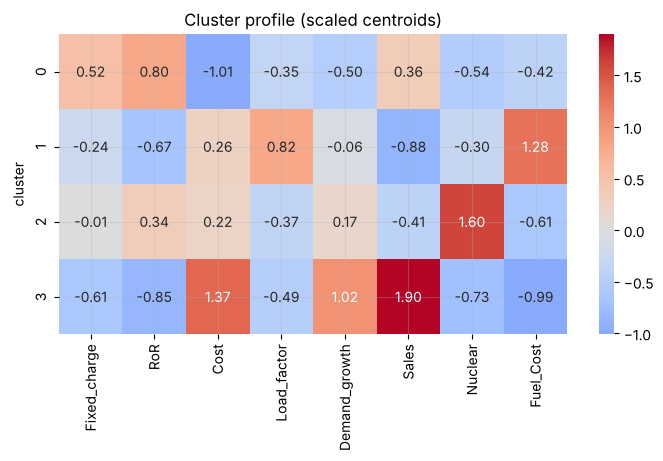

✍️ Cluster 0 (n=7): สูง → Fixed_charge, RoR | ต่ำ → Cost, Demand_growth, Nuclear
✍️ Cluster 1 (n=7): สูง → Load_factor, Fuel_Cost | ต่ำ → RoR, Sales
✍️ Cluster 2 (n=5): สูง → Nuclear | ต่ำ → Fuel_Cost
✍️ Cluster 3 (n=3): สูง → Cost, Demand_growth, Sales | ต่ำ → Fixed_charge, RoR, Nuclear, Fuel_Cost


In [5]:
km = KMeans(n_clusters=K, n_init=N_INIT, max_iter=MAX_ITER, random_state=SEED).fit(Z)
data["cluster"] = km.labels_
print(f"k = {K} · WCSS = {km.inertia_:.4f} · silhouette = {silhouette_score(Z, km.labels_):.4f} · iterations = {km.n_iter_}")
for c in range(K):
    mem = names[data.cluster == c].tolist()
    print(f"Cluster {c} ({len(mem)}): {', '.join(mem[:30])}{' …' if len(mem) > 30 else ''}")
cent_orig = data.groupby("cluster")[feats].mean()                       # centroid หน่วยเดิม
cent_z = pd.DataFrame(km.cluster_centers_, columns=feats)               # centroid หลัง scale
print("\ncentroid (หน่วยเดิม) + ค่าเฉลี่ยรวม:"); display(pd.concat([cent_orig, Xc.mean().to_frame("ALL").T]).round(3))
print("centroid (scaled; + = สูงกว่าค่าเฉลี่ย, − = ต่ำกว่า):"); display(cent_z.round(3))
plt.figure(figsize=(1 + 0.9 * len(feats), 0.6 * K + 1.5))
sns.heatmap(cent_z, annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.title("Cluster profile (scaled centroids)"); plt.ylabel("cluster"); plt.show()
# คำอธิบายอัตโนมัติ: ตัวแปรที่ |z| ≥ 0.5
for c in range(K):
    hi = [f for f in feats if cent_z.loc[c, f] >= 0.5]; lo = [f for f in feats if cent_z.loc[c, f] <= -0.5]
    print(f"✍️ Cluster {c} (n={int((data.cluster == c).sum())}): สูง → {', '.join(hi) or '-'} | ต่ำ → {', '.join(lo) or '-'}")

**✍️ คำตอบ §3:** Cluster 0 = … (… สูง, … ต่ำ) → ตั้งชื่อ "…" · Cluster 1 = … · …

## §4 จุดใหม่อยู่ cluster ไหน (scale ด้วย scaler ตัวเดิม → หา centroid ที่ใกล้สุด)

In [6]:
if NEW_POINT is not None:
    newp = new_data(NEW_POINT)[feats]
    zn = scaler.transform(newp) if scaler else newp.values
    d = np.sqrt(((km.cluster_centers_ - zn) ** 2).sum(axis=1))
    display(pd.DataFrame({"distance to centroid": d}, index=[f"cluster {c}" for c in range(K)]).round(4))
    print("จุดใหม่หลัง scale:", np.round(zn[0], 3))
    print(f"✍️ จุดใหม่อยู่ cluster {int(km.predict(zn)[0])} (ระยะถึง centroid ใกล้สุด = {d.min():.4f})")

,distance to centroid
cluster 0,1.7378
cluster 1,3.4269
cluster 2,3.0504
cluster 3,2.2867


จุดใหม่หลัง scale: [-0.078  0.12  -0.203 -0.224 -0.079  1.466 -0.731 -0.741]
✍️ จุดใหม่อยู่ cluster 0 (ระยะถึง centroid ใกล้สุด = 1.7378)


## §5 Cohesion & Separation + silhouette ต่อกลุ่ม
- **Cohesion** = ความแน่นในกลุ่ม (WCSS ต่อกลุ่ม, ระยะเฉลี่ยถึง centroid) — ยิ่งต่ำยิ่งดี
- **Separation** = ระยะห่างระหว่าง centroid — ยิ่งมากยิ่งดี

In [7]:
sil = silhouette_samples(Z, km.labels_)
coh = []
for c in range(K):
    Zc = Z[km.labels_ == c]; d = np.sqrt(((Zc - km.cluster_centers_[c]) ** 2).sum(axis=1))
    coh.append({"cluster": c, "n": len(Zc), "WCSS": (d ** 2).sum(), "avg dist to centroid": d.mean(), "avg silhouette": sil[km.labels_ == c].mean()})
display(pd.DataFrame(coh).round(4))
sep = pd.DataFrame(np.sqrt(((km.cluster_centers_[:, None, :] - km.cluster_centers_[None, :, :]) ** 2).sum(-1)),
                   index=[f"C{c}" for c in range(K)], columns=[f"C{c}" for c in range(K)])
print("ระยะระหว่าง centroid (separation):"); display(sep.round(3))
neg = names[sil < 0].tolist()
print(f"✍️ silhouette เฉลี่ย {sil.mean():.4f} · จุดที่ silhouette < 0 (อาจอยู่ผิดกลุ่ม): {neg or '-'}")

,cluster,n,WCSS,avg dist to centroid,avg silhouette
0,0,7,27.7700,1.9525,0.1798
1,1,7,35.7917,2.0885,0.1631
2,2,5,10.6617,1.4307,0.3718
3,3,3,9.9875,1.7991,0.2969


ระยะระหว่าง centroid (separation):


,C0,C1,C2,C3
C0,0.0000,3.2250,2.7680,3.8360
C1,3.2250,0.0000,3.1500,4.1620
C2,2.7680,3.1500,0.0000,3.8420
C3,3.8360,4.1620,3.8420,0.0000


✍️ silhouette เฉลี่ย 0.2341 · จุดที่ silhouette < 0 (อาจอยู่ผิดกลุ่ม): ['Boston', 'NY']


## §6 ภาพ cluster บน PCA 2D (ใส่ชื่อจุด)

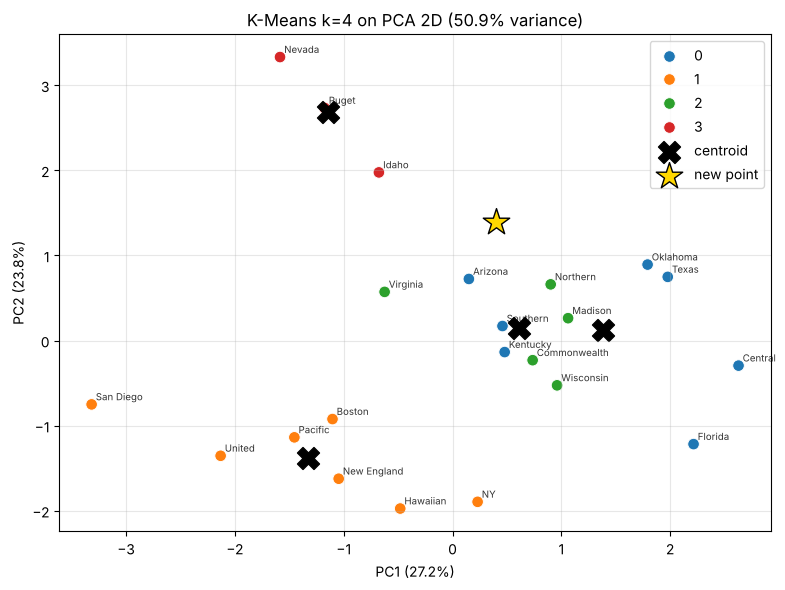

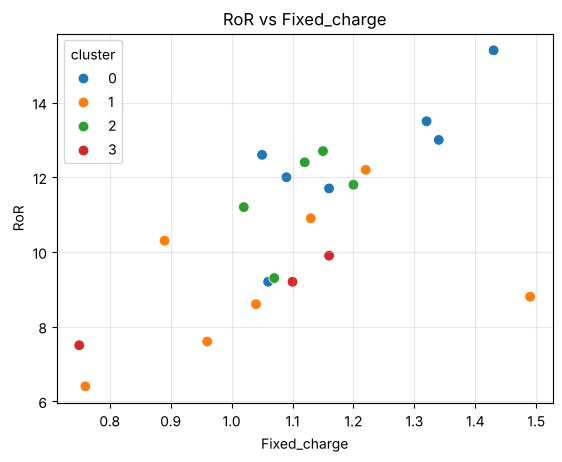

In [8]:
pca = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca.transform(Z); C = pca.transform(km.cluster_centers_)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=data.cluster.astype(str), palette="tab10", s=70)
plt.scatter(C[:, 0], C[:, 1], marker="X", s=250, c="k", label="centroid")
if len(data) <= 80:
    for i, n in enumerate(names):
        plt.annotate(n, P[i], fontsize=7, alpha=.8, xytext=(3, 3), textcoords="offset points")
if NEW_POINT is not None:
    pn = pca.transform(zn); plt.scatter(pn[:, 0], pn[:, 1], marker="*", s=400, c="gold", edgecolor="k", label="new point")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title(f"K-Means k={K} on PCA 2D ({pca.explained_variance_ratio_.sum():.1%} variance)"); plt.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()
# scatter 2 feature เดิม (✏️ เลือกคู่)
FX, FY = feats[0], feats[1]
sns.scatterplot(data=data, x=FX, y=FY, hue=data.cluster.astype(str), palette="tab10", s=60); plt.title(f"{FY} vs {FX}"); plt.show()

**✍️ คำตอบ §6:** บนภาพ PCA (…% ของความแปรปรวน) cluster … แยกชัด (separation ดี) · cluster … กับ … อยู่ใกล้กัน/ซ้อนบางส่วน · จุด … อยู่ขอบกลุ่ม

## §7 Hierarchical clustering + Dendrogram
- agglomerative: เริ่มทุกจุดเป็นกลุ่มเดี่ยว → รวมคู่ที่ใกล้สุดทีละขั้น
- linkage: **single** (ระยะคู่ที่ใกล้สุด) · **complete** (ไกลสุด) · **average** · **ward** (เพิ่ม WCSS น้อยสุด)
- ตัด dendrogram ที่ความสูงที่ทำให้ได้ k กลุ่ม

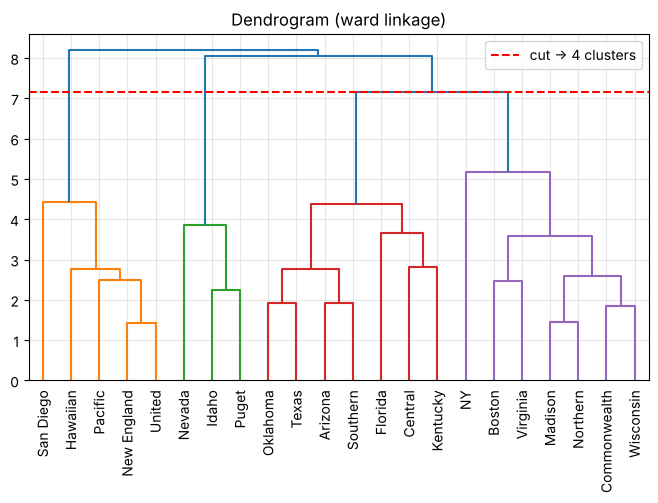

hierarchical (ward) silhouette = 0.2431 vs K-Means 0.2341
เทียบ K-Means (แถว) กับ Hierarchical (คอลัมน์):


hier,0,1,2,3
cluster,,,,
0,0,0,7,0
1,5,0,0,2
2,0,0,0,5
3,0,3,0,0


H0: Hawaiian, New England, Pacific, San Diego, United
H1: Idaho, Nevada, Puget
H2: Arizona, Central, Florida, Kentucky, Oklahoma, Southern, Texas
H3: Boston, Commonwealth, NY, Madison, Northern, Wisconsin, Virginia


In [9]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
Lk = linkage(Z, method=LINKAGE)
plt.figure(figsize=(max(8, 0.35 * len(data)), 4.5))
dendrogram(Lk, labels=names.tolist() if len(data) <= 80 else None, leaf_rotation=90, color_threshold=Lk[-(K - 1), 2])
plt.axhline(Lk[-(K - 1), 2], color="r", ls="--", label=f"cut → {K} clusters"); plt.title(f"Dendrogram ({LINKAGE} linkage)"); plt.legend(); plt.show()
data["hier"] = fcluster(Lk, t=K, criterion="maxclust") - 1
print(f"hierarchical ({LINKAGE}) silhouette = {silhouette_score(Z, data.hier):.4f} vs K-Means {silhouette_score(Z, km.labels_):.4f}")
print("เทียบ K-Means (แถว) กับ Hierarchical (คอลัมน์):"); display(pd.crosstab(data.cluster, data.hier))
for c in sorted(data.hier.unique()):
    print(f"H{c}: {', '.join(names[data.hier == c].tolist()[:30])}")

## §8 เทียบกับ label จริง (ถ้ามี — ใช้ประเมินภายนอกเท่านั้น)

In [10]:
if LABEL_COL and LABEL_COL in data:
    from sklearn.metrics import adjusted_rand_score
    display(pd.crosstab(data[LABEL_COL], data.cluster, margins=True))
    print(f"✍️ Adjusted Rand Index = {adjusted_rand_score(data[LABEL_COL], data.cluster):.4f} (1 = ตรงกันสมบูรณ์, 0 = สุ่ม)")
else:
    print("ไม่มี LABEL_COL → ข้าม")
data.to_csv("t10_clusters.csv", index=False); print("saved t10_clusters.csv")

ไม่มี LABEL_COL → ข้าม
saved t10_clusters.csv


## §9 K-Means ทีละรอบด้วยมือ (โจทย์ให้จุดเล็ก ๆ + centroid เริ่มต้น)
✏️ ใส่จุดใน `HAND_POINTS` และ `HAND_INIT` (ชื่อจุดที่เป็น seed หรือพิกัด centroid เริ่มต้น) · ไม่ scale (ตามตำรา) ·
แต่ละรอบ: คำนวณระยะทุกจุด → จัดเข้า centroid ที่ใกล้สุด → คำนวณ centroid ใหม่ = ค่าเฉลี่ยสมาชิก → หยุดเมื่อสมาชิกไม่เปลี่ยน

══ Iteration 1


,"d(C1=(3.0, 8.0))","d(C2=(2.0, 2.0))","d(C3=(6.0, 8.0))",→ cluster
A1,0.0000,6.0830,3.0000,C1
A2,7.2110,7.2800,5.0000,C3
A3,1.4140,7.2800,2.2360,C1
A4,6.0830,0.0000,7.2110,C2
A5,7.6160,8.5440,5.0000,C3
A6,4.1230,2.0000,5.6570,C2
A7,3.0000,7.2110,0.0000,C3
A8,5.0990,2.2360,5.3850,C2
A9,1.4140,5.3850,2.2360,C1


   C1: ['A1', 'A3', 'A9'] → centroid ใหม่ = (3.667, 8.0)
   C2: ['A4', 'A6', 'A8'] → centroid ใหม่ = (2.667, 3.0)
   C3: ['A2', 'A5', 'A7'] → centroid ใหม่ = (8.333, 5.667)
   SSE (กับ centroid ใหม่) = 24.6667
══ Iteration 2


,"d(C1=(3.67, 8.0))","d(C2=(2.67, 3.0))","d(C3=(8.33, 5.67))",→ cluster
A1,0.6670,5.0110,5.8210,C1
A2,6.6670,6.4120,1.7950,C3
A3,1.0540,6.1460,5.4670,C1
A4,6.2270,1.2020,7.3180,C2
A5,7.0080,7.6010,1.7950,C3
A6,4.3330,1.2020,6.5490,C2
A7,2.3330,6.0090,3.3000,C1
A8,5.0110,1.3330,5.0880,C2
A9,1.0540,4.2160,4.5340,C1


   C1: ['A1', 'A3', 'A7', 'A9'] → centroid ใหม่ = (4.25, 8.0)
   C2: ['A4', 'A6', 'A8'] → centroid ใหม่ = (2.667, 3.0)
   C3: ['A2', 'A5'] → centroid ใหม่ = (9.5, 4.5)
   SSE (กับ centroid ใหม่) = 12.4167
══ Iteration 3


,"d(C1=(4.25, 8.0))","d(C2=(2.67, 3.0))","d(C3=(9.5, 4.5))",→ cluster
A1,1.2500,5.0110,7.3820,C1
A2,6.2100,6.4120,0.7070,C3
A3,1.0310,6.1460,7.1060,C1
A4,6.4080,1.2020,7.9060,C2
A5,6.4860,7.6010,0.7070,C3
A6,4.5890,1.2020,7.5170,C2
A7,1.7500,6.0090,4.9500,C1
A8,5.0060,1.3330,5.7010,C2
A9,1.0310,4.2160,6.0420,C1


   C1: ['A1', 'A3', 'A7', 'A9'] → centroid ใหม่ = (4.25, 8.0)
   C2: ['A4', 'A6', 'A8'] → centroid ใหม่ = (2.667, 3.0)
   C3: ['A2', 'A5'] → centroid ใหม่ = (9.5, 4.5)
   SSE (กับ centroid ใหม่) = 12.4167
✍️ สมาชิกไม่เปลี่ยนจากรอบก่อน → converge ที่ iteration 3


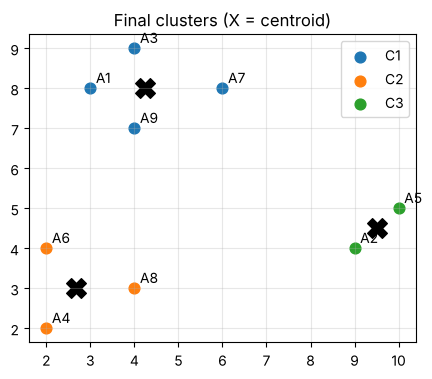

In [11]:
HAND_POINTS = {"A1": (3, 8), "A2": (9, 4), "A3": (4, 9), "A4": (2, 2), "A5": (10, 5),   # ✏️ ชื่อ: (x, y, ...)
               "A6": (2, 4), "A7": (6, 8), "A8": (4, 3), "A9": (4, 7)}
HAND_INIT   = ["A1", "A4", "A7"]      # ✏️ ชื่อจุดที่เป็น seed · หรือพิกัดตรง ๆ เช่น [(2, 10), (5, 8), (1, 2)]
HAND_DIST   = "euclidean"             # ✏️ "euclidean" | "manhattan"
HAND_SHOW_SQUARED = False             # ✏️ True = แสดงระยะยกกำลังสอง (ไม่ถอดราก) แบบที่บางโจทย์ใช้

hn = list(HAND_POINTS); HP = np.array(list(HAND_POINTS.values()), dtype=float)
cent = np.array([HAND_POINTS[c] if isinstance(c, str) else c for c in HAND_INIT], dtype=float)
kh = len(cent); prev = None
for it in range(1, 21):
    diff = HP[:, None, :] - cent[None, :, :]
    dist = np.abs(diff).sum(-1) if HAND_DIST == "manhattan" else ((diff ** 2).sum(-1) if HAND_SHOW_SQUARED else np.sqrt((diff ** 2).sum(-1)))
    lab = dist.argmin(axis=1)
    tab = pd.DataFrame(dist, index=hn, columns=[f"d(C{j + 1}={tuple(np.round(cent[j], 2).tolist())})" for j in range(kh)]).round(3)
    tab["→ cluster"] = [f"C{l + 1}" for l in lab]
    print(f"══ Iteration {it}"); display(tab)
    new = np.array([HP[lab == j].mean(axis=0) if (lab == j).any() else cent[j] for j in range(kh)])
    sse = sum(((HP[lab == j] - new[j]) ** 2).sum() for j in range(kh))
    for j in range(kh):
        print(f"   C{j + 1}: {[n for n, l in zip(hn, lab) if l == j]} → centroid ใหม่ = {tuple(np.round(new[j], 3).tolist())}")
    print(f"   SSE (กับ centroid ใหม่) = {sse:.4f}")
    if prev is not None and (lab == prev).all():
        print(f"✍️ สมาชิกไม่เปลี่ยนจากรอบก่อน → converge ที่ iteration {it}"); break
    prev, cent = lab, new
if HP.shape[1] == 2:
    plt.figure(figsize=(5, 4))
    for j in range(kh):
        plt.scatter(*HP[lab == j].T, s=60, label=f"C{j + 1}"); plt.scatter(*new[j], marker="X", s=200, c="k")
    for n, (x0, y0) in zip(hn, HP):
        plt.annotate(n, (x0, y0), xytext=(4, 4), textcoords="offset points")
    plt.title("Final clusters (X = centroid)"); plt.legend(); plt.show()